# Atropelamentos em São Paulo (2022–2025): entorno dos pontos críticos (escolas e semáforos)

**Pré-requisito:** rodar antes o notebook `03_dbscan_pontos_criticos.ipynb`, que cria o banco
`data/processed/seguranca_viaria.db` com a tabela `clusters`.

**Pergunta:** o que existe em volta de cada concentração de atropelamentos? Mais especificamente:

1. há **escola** perto? Isso justifica o modo **"escola"** do nó, que muda o semáforo e a sinalização nos
   horários de entrada e saída;
2. há **semáforo**? Um ponto crítico sem semáforo é candidato ao modo **"pedestre"** (travessia acionada e
   aviso ao motorista), e um ponto com semáforo pode receber ajuste de tempo de travessia;
3. com isso, **o Largo da Concórdia se confirma como piloto?**

Este é o passo 4 do método (enriquecer os grupos com o entorno urbano) e responde ao item "O que ainda falta
confirmar" do planejamento.

**Fonte:** GeoSampa (Prefeitura de São Paulo), baixado pelo serviço WFS público
(`wfs.geosampa.prefeitura.sp.gov.br`) em GeoJSON, coordenadas WGS84 (EPSG:4326).

## 1. Configuração

In [1]:
from pathlib import Path
import json, sqlite3, unicodedata, urllib.request, datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium
from sklearn.neighbors import BallTree

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
RAW_GEO = ROOT / "data" / "raw" / "geosampa"
RAW_GEO.mkdir(parents=True, exist_ok=True)
PROCESSED = ROOT / "data" / "processed"
EVID = ROOT / "docs" / "evidencias" / "estudo_b"
DB_PATH = PROCESSED / "seguranca_viaria.db"
R_TERRA = 6_371_000

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

def salvar(fig, nome):
    fig.savefig(EVID / nome, dpi=150, bbox_inches="tight", facecolor="white")

## 2. Camadas do GeoSampa

| Camada (WFS `geoportal:`) | O que tem |
|---|---|
| `equipamento_educacao_rede_publica` | escolas **estaduais** (EE) e **municipais** de ensino fundamental e médio (EMEF, EMEFM) |
| `equipamento_educacao_infantil_rede_publica` | educação infantil municipal: EMEI e CEMEI (pré-escola), CEI e creches conveniadas |
| `equipamento_educacao_ceu` | unidades escolares dentro dos CEUs (CEU EMEF, CEU EMEI, CEU CEI) |
| `semaforo` | cadastro de semáforos da CET (um ponto por local semaforizado), tipo `COMUM` ou `PISCANTE` |

**Download:** os arquivos ficam em `data/raw/geosampa/`, com a data do download no nome. Se não existirem,
a célula abaixo baixa do WFS. Por isso `data/raw/` pode continuar fora do Git (regra do template) e o
notebook continua reproduzível. Quando há mais de uma data, usamos a mais recente.

In [2]:
WFS = ("https://wfs.geosampa.prefeitura.sp.gov.br/geoserver/geoportal/wfs?service=WFS&version=2.0.0"
       "&request=GetFeature&typeNames=geoportal:{camada}&outputFormat=application/json&srsName=EPSG:4326")
CAMADAS = ["equipamento_educacao_rede_publica", "equipamento_educacao_infantil_rede_publica",
           "equipamento_educacao_ceu", "semaforo"]

def camada_local(camada: str) -> Path:
    """Arquivo mais recente da camada; baixa do WFS se não houver nenhum."""
    existentes = sorted(RAW_GEO.glob(f"geosampa_{camada}_*.geojson"))
    if existentes:
        return existentes[-1]
    destino = RAW_GEO / f"geosampa_{camada}_{dt.date.today().isoformat()}.geojson"
    req = urllib.request.Request(WFS.format(camada=camada), headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=300) as r:
        destino.write_bytes(r.read())
    return destino

def ler_pontos(camada: str) -> pd.DataFrame:
    arq = camada_local(camada)
    fc = json.loads(arq.read_text(encoding="utf-8"))
    assert "4326" in json.dumps(fc.get("crs", {})), f"{arq.name}: esperado EPSG:4326"
    linhas = []
    for f in fc["features"]:
        g = f["geometry"]
        if g and g["type"] == "Point":
            lon, lat = g["coordinates"][:2]
            linhas.append({**f["properties"], "latitude": lat, "longitude": lon})
    df = pd.DataFrame(linhas).assign(camada=camada, arquivo=arq.name)
    df.attrs["descartados"] = len(fc["features"]) - len(linhas)  # sem geometria ou geometria que não é ponto
    return df

brutos = {c: ler_pontos(c) for c in CAMADAS}
pd.DataFrame({"arquivo": [d["arquivo"].iloc[0] for d in brutos.values()],
              "pontos": [len(d) for d in brutos.values()],
              "descartados (sem ponto)": [d.attrs["descartados"] for d in brutos.values()]}, index=CAMADAS)

,arquivo,pontos,descartados (sem ponto)
equipamento_educacao_rede_publica,geosampa_equipamento_educacao_rede_publica_202...,1597,0
equipamento_educacao_infantil_rede_publica,geosampa_equipamento_educacao_infantil_rede_pu...,3041,0
equipamento_educacao_ceu,geosampa_equipamento_educacao_ceu_2026-11-11.g...,150,0
semaforo,geosampa_semaforo_2026-11-11.geojson,6419,13


### 2.1 O que conta como "escola"

**Decisão:** para o modo escola, interessa o lugar onde há **entrada e saída concentrada de crianças e
adolescentes a pé, em horário fixo**. Entram:

- **EE, EMEF e EMEFM** (ensino fundamental e médio, estaduais e municipais): alunos que atravessam sozinhos;
- **EMEI e CEMEI** (pré-escola municipal): crianças pequenas com acompanhante, em horário fixo;
- **unidades dos CEUs** (EMEF, EMEI e CEI do CEU).

**Ficam fora as creches** (CEI direto ou indireto e creches particulares conveniadas, ~2,5 mil pontos). Elas
atendem crianças de 0 a 3 anos, que chegam no colo ou de carrinho, em horários espalhados. Contá-las
inflaria o indicador sem relação com a travessia escolar. Elas aparecem numa coluna separada, só para
consulta.

**Unidades no mesmo endereço** (CEU com EMEF + EMEI + CEI, escola estadual e municipal no mesmo prédio)
contam como **um local**: arredondamos a coordenada a ~10 m e juntamos os nomes.

**Semáforos:** só os do tipo **`COMUM`** contam como semáforo. O `PISCANTE` (amarelo intermitente) não tem
fase para o pedestre e não organiza a travessia, então é contado à parte.

In [3]:
def sem_acento(x):
    return unicodedata.normalize("NFKD", x).encode("ascii", "ignore").decode() if isinstance(x, str) else x

TIPOS_INFANTIL_ESCOLA = {"EMEI", "CEMEI"}
esc = pd.concat([
    brutos["equipamento_educacao_rede_publica"].query("nm_esfera_administrativa_equipamento != 'PRIVADA'"),
    brutos["equipamento_educacao_infantil_rede_publica"].query("nm_tipo_equipamento in @TIPOS_INFANTIL_ESCOLA"),
    brutos["equipamento_educacao_ceu"],
], ignore_index=True)
creches = brutos["equipamento_educacao_infantil_rede_publica"].query("nm_tipo_equipamento not in @TIPOS_INFANTIL_ESCOLA")

esc["rede"] = esc["nm_esfera_administrativa_equipamento"].str.replace("ESTADUAL-SE", "ESTADUAL")
esc["chave_local"] = list(zip(esc["latitude"].round(4), esc["longitude"].round(4)))
escolas = (esc.groupby("chave_local", sort=False)
              .agg(latitude=("latitude", "mean"), longitude=("longitude", "mean"),
                   nomes=("nm_equipamento", lambda s: " / ".join(dict.fromkeys(s.str.strip()))),
                   tipos=("nm_tipo_equipamento", lambda s: " / ".join(dict.fromkeys(s.str.strip()))),
                   redes=("rede", lambda s: " / ".join(dict.fromkeys(s))),
                   unidades=("nm_equipamento", "size"))
              .reset_index(drop=True))

sem = brutos["semaforo"]
semaforos = sem[sem["dc_tipo_semaforo"].eq("COMUM")].reset_index(drop=True)
piscantes = sem[sem["dc_tipo_semaforo"].eq("PISCANTE")].reset_index(drop=True)

print(f"escolas: {len(esc):,} unidades em {len(escolas):,} locais "
      f"({(esc['rede'] == 'ESTADUAL').sum():,} estaduais, {(esc['rede'] == 'MUNICIPAL').sum():,} municipais)")
print(f"creches (fora do indicador): {len(creches):,}")
print(f"semáforos comuns: {len(semaforos):,} | piscantes (à parte): {len(piscantes):,} | "
      f"data de carga do cadastro: {sorted(sem['dt_carga'].str[:10].unique())}")
esc.groupby(["rede", "nm_tipo_equipamento"]).size().rename("unidades").to_frame()

escolas: 2,283 unidades em 2,178 locais (1,036 estaduais, 1,247 municipais)
creches (fora do indicador): 2,504
semáforos comuns: 5,844 | piscantes (à parte): 575 | data de carga do cadastro: ['2018-03-02']


unidades
rede      nm_tipo_equipamento          
ESTADUAL  EE                       1036
MUNICIPAL CEMEI                      33
          CEU CEI                    45
          CEU EMEF                   46
          CEU EMEI                   47
          EMEF                      552
          EMEFM                       8
          EMEI                      516

## 3. Entorno de cada grupo

Para cada grupo da tabela `clusters`, a partir do **centróide** do grupo:

| Coluna | Definição | Por que esse raio |
|---|---|---|
| `n_escolas_300m` | locais de escola a até 300 m | ~4 minutos a pé: a área em que o fluxo de entrada e saída ainda passa pela mesma travessia. É também a ordem de grandeza usada em programas de "rota escolar" e zonas escolares de velocidade reduzida |
| `distancia_escola_mais_proxima_m` | distância até a escola mais próxima | para ordenar grupos sem escola dentro dos 300 m |
| `n_semaforos_150m` | semáforos **comuns** a até 150 m | a extensão mediana dos grupos é ~175 m, então 150 m do centro cobre o trecho do grupo e o cruzamento vizinho |
| `tem_semaforo` | `n_semaforos_150m > 0` | |

As distâncias são **haversine** (em linha reta sobre a esfera), calculadas com `BallTree`, a mesma métrica
do DBSCAN. Linha reta subestima o caminho a pé real, porque o pedestre segue as ruas.

In [4]:
con = sqlite3.connect(DB_PATH)
clusters = pd.read_sql_query("SELECT * FROM clusters ORDER BY rank_prioridade", con)
sin = pd.read_sql_query("SELECT cluster_id, logradouro FROM sinistros WHERE cluster_id IS NOT NULL", con)
con.close()
sin["via"] = sin["logradouro"].map(sem_acento)
vias = sin.groupby("cluster_id")["via"].agg(lambda s: " | ".join(s.dropna().value_counts().head(3).index))
clusters["vias"] = clusters["cluster_id"].map(vias)
print(f"{len(clusters)} grupos lidos do banco ({clusters['rank_urbano'].notna().sum()} no ranking urbano)")

rad = lambda df, la="latitude", lo="longitude": np.radians(df[[la, lo]].to_numpy())
C = rad(clusters, "lat_centro", "lon_centro")
arv_esc, arv_sem, arv_pis, arv_cre = (BallTree(rad(d), metric="haversine")
                                     for d in (escolas, semaforos, piscantes, creches))

idx_esc = arv_esc.query_radius(C, r=300 / R_TERRA)
dist_esc, prox_esc = arv_esc.query(C, k=1)
clusters["n_escolas_300m"] = [len(i) for i in idx_esc]
clusters["distancia_escola_mais_proxima_m"] = (dist_esc[:, 0] * R_TERRA).round(1)
clusters["n_semaforos_150m"] = arv_sem.query_radius(C, r=150 / R_TERRA, count_only=True)
clusters["tem_semaforo"] = clusters["n_semaforos_150m"] > 0
clusters["n_piscantes_150m"] = arv_pis.query_radius(C, r=150 / R_TERRA, count_only=True)
clusters["n_creches_300m"] = arv_cre.query_radius(C, r=300 / R_TERRA, count_only=True)
clusters["escolas_300m"] = [" ; ".join(escolas.loc[i, "nomes"]) for i in idx_esc]

clusters[["n_escolas_300m", "distancia_escola_mais_proxima_m", "n_semaforos_150m", "n_piscantes_150m",
          "n_creches_300m"]].describe().round(1).T

290 grupos lidos do banco (273 no ranking urbano)


,count,mean,std,min,25%,50%,75%,max
n_escolas_300m,290.0,0.7,1.0,0.0,0.0,0.0,1.0,5.0
distancia_escola_mais_proxima_m,290.0,348.1,211.2,28.3,196.2,315.6,452.6,1757.9
n_semaforos_150m,290.0,1.9,1.7,0.0,1.0,2.0,3.0,9.0
n_piscantes_150m,290.0,0.1,0.4,0.0,0.0,0.0,0.0,2.0
n_creches_300m,290.0,0.9,1.5,0.0,0.0,0.0,1.0,13.0


### 3.1 Gravar no banco (`ALTER TABLE`, sem apagar dados)

As 4 colunas pedidas entram na tabela `clusters` com `ALTER TABLE ... ADD COLUMN`, e os valores com
`UPDATE` por `cluster_id`. Nada é apagado nem recriado. Se a coluna já existir (notebook rodado de novo),
só os valores são atualizados. `tem_semaforo` é gravado como 0/1, porque o SQLite não tem tipo booleano.

Se o notebook 03 for rodado de novo, ele recria o banco do zero e estas colunas somem. Basta rodar este
notebook outra vez em seguida.

In [5]:
NOVAS = {"n_escolas_300m": "INTEGER", "distancia_escola_mais_proxima_m": "REAL",
         "n_semaforos_150m": "INTEGER", "tem_semaforo": "INTEGER CHECK (tem_semaforo IN (0, 1))"}
with sqlite3.connect(DB_PATH) as con:
    antes = con.execute("SELECT COUNT(*) FROM clusters").fetchone()[0]
    existentes = {r[1] for r in con.execute("PRAGMA table_info(clusters)")}
    for col, tipo in NOVAS.items():
        if col not in existentes:
            con.execute(f"ALTER TABLE clusters ADD COLUMN {col} {tipo}")
    con.executemany(
        "UPDATE clusters SET n_escolas_300m = ?, distancia_escola_mais_proxima_m = ?, n_semaforos_150m = ?, "
        "tem_semaforo = ? WHERE cluster_id = ?",
        [(int(r.n_escolas_300m), float(r.distancia_escola_mais_proxima_m), int(r.n_semaforos_150m),
          int(r.tem_semaforo), int(r.cluster_id)) for r in clusters.itertuples()])
    depois = con.execute("SELECT COUNT(*) FROM clusters").fetchone()[0]
    nulos = con.execute("SELECT COUNT(*) FROM clusters WHERE n_escolas_300m IS NULL OR tem_semaforo IS NULL").fetchone()[0]
assert antes == depois and nulos == 0
print(f"clusters: {depois} linhas (antes: {antes}) | colunas novas preenchidas em todas as linhas")
with sqlite3.connect(DB_PATH) as con:
    display(pd.read_sql_query("PRAGMA table_info(clusters)", con)[["name", "type"]].tail(6))

clusters: 290 linhas (antes: 290) | colunas novas preenchidas em todas as linhas


,name,type
14,min_samples,INTEGER
15,criado_em,TEXT
16,n_escolas_300m,INTEGER
17,distancia_escola_mais_proxima_m,REAL
18,n_semaforos_150m,INTEGER
19,tem_semaforo,INTEGER


## 4. Top 50: escolas e semáforos

Comparamos o **top 50 urbano** (o ranking usado para decidir intervenção, ver notebook 03, seção 3.2) com o
**top 50 geral** e com o conjunto de todos os grupos, que serve de referência: "60% do top 50 tem escola"
só diz algo se comparado com a taxa dos demais.

In [6]:
recortes = {"top 50 urbano": clusters[clusters["rank_urbano"].between(1, 50)],
            "top 50 geral": clusters[clusters["rank_prioridade"] <= 50],
            "todos os grupos": clusters}
resumo = pd.DataFrame({
    nome: {"grupos": len(d),
           "com escola a até 300 m": int((d["n_escolas_300m"] > 0).sum()),
           "% com escola": round((d["n_escolas_300m"] > 0).mean() * 100, 1),
           "sem semáforo a até 150 m": int((~d["tem_semaforo"]).sum()),
           "% sem semáforo": round((~d["tem_semaforo"]).mean() * 100, 1),
           "escola E sem semáforo": int(((d["n_escolas_300m"] > 0) & ~d["tem_semaforo"]).sum()),
           "distância mediana à escola (m)": round(d["distancia_escola_mais_proxima_m"].median())}
    for nome, d in recortes.items()}).T.convert_dtypes()
resumo

,grupos,com escola a até 300 m,% com escola,sem semáforo a até 150 m,% sem semáforo,escola E sem semáforo,distância mediana à escola (m)
top 50 urbano,50,20,40.0,9,18.0,5,343
top 50 geral,50,17,34.0,18,36.0,4,378
todos os grupos,290,140,48.3,53,18.3,22,316


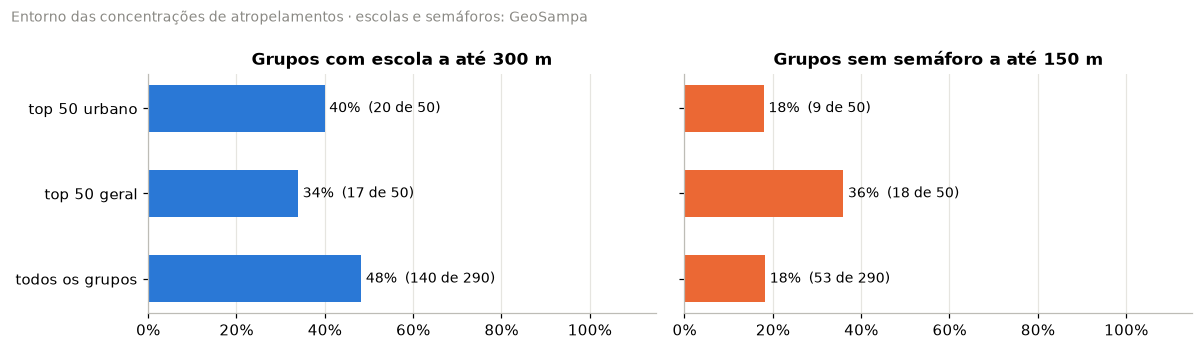

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
y = np.arange(len(resumo))[::-1]
for ax, col, col_n, cor, titulo in [
        (axes[0], "% com escola", "com escola a até 300 m", AZUL, "Grupos com escola a até 300 m"),
        (axes[1], "% sem semáforo", "sem semáforo a até 150 m", LARANJA, "Grupos sem semáforo a até 150 m")]:
    ax.barh(y, resumo[col], color=cor, height=0.55)
    for yi, v, n, tot in zip(y, resumo[col], resumo[col_n], resumo["grupos"]):
        ax.text(v + 1, yi, f"{v:.0f}%  ({int(n)} de {int(tot)})", va="center", fontsize=9)
    ax.set_xlim(0, 115); ax.set_title(titulo, fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y); axes[0].set_yticklabels(resumo.index)
fig.suptitle("Entorno das concentrações de atropelamentos · escolas e semáforos: GeoSampa", x=0.01, ha="left",
             fontsize=9, color=CINZA)
fig.tight_layout()
salvar(fig, "04_top50_escolas_semaforos.png")
plt.show()

**Leitura:** o resultado **não** é "os pontos críticos ficam perto de escola".

- **Escolas:** 20 dos 50 primeiros do ranking urbano (40%) têm escola a até 300 m. Entre todos os grupos a
  taxa é **maior** (48%). Isso é esperado, porque a cidade tem ~2,2 mil locais de escola pública e numa área
  densa quase todo ponto tem uma escola por perto. Escola não explica a concentração de atropelamentos. O
  argumento para o modo **"escola"** é **local, ponto a ponto**: em 20 dos 50 pontos mais críticos existe
  entrada e saída de alunos dentro do raio, e é nesses pontos que o modo faz sentido.
- **Semáforos:** 9 dos 50 primeiros (18%) **não têm semáforo comum** a até 150 m, a mesma taxa do conjunto.
  Nesses pontos o pedestre atravessa sem controle nenhum, e é aí que o modo **"pedestre"** (travessia
  acionada pelo botão ou pela detecção, com aviso ao motorista) muda mais a situação. Nos outros 41, o nó atua
  **sobre um semáforo que já existe**, ajustando o tempo de travessia. Isso é mais barato e é o cenário do
  piloto.
- No top 50 **geral**, 36% ficam sem semáforo porque ali entram as rodovias (BR 381, SP 330), que não têm
  semáforo. É mais um motivo para usar o ranking urbano na decisão.

In [8]:
cols = ["rank_urbano", "rank_prioridade", "via_principal", "n_nao_fatais", "n_fatais", "indice_cet",
        "n_escolas_300m", "distancia_escola_mais_proxima_m", "n_semaforos_150m", "n_piscantes_150m"]
alvo = clusters[clusters["rank_urbano"].between(1, 50)]
print("Top 50 urbano: com escola a até 300 m E sem semáforo comum a até 150 m (candidatos aos modos escola + pedestre)")
alvo[(alvo["n_escolas_300m"] > 0) & ~alvo["tem_semaforo"]][cols].round(2)

Top 50 urbano: com escola a até 300 m E sem semáforo comum a até 150 m (candidatos aos modos escola + pedestre)


,rank_urbano,rank_prioridade,via_principal,n_nao_fatais,n_fatais,indice_cet,n_escolas_300m,distancia_escola_mais_proxima_m,n_semaforos_150m,n_piscantes_150m
22,10.0,23,RUA DEMAS ZITTO,5,1,6.68,5,97.5,0,0
56,42.0,57,AVENIDA JACUPESSEGO,8,1,11.48,1,227.6,0,0
58,44.0,59,ESTRADA CANAL DE COCAIA,4,2,11.67,5,31.3,0,0
60,46.0,61,ESTRADA DO CAMPO LIMPO,2,2,11.84,2,256.2,0,0
61,47.0,62,RUA ANTONIO DE FRANCA E SILVA,3,2,11.91,1,254.5,0,0


**Leitura:** cinco pontos do top 50 urbano juntam **escola por perto e nenhum semáforo**: Rua Demas Zitto
(10º, 5 escolas, a mais próxima a ~100 m), Estrada Canal de Cocaia (44º, 5 escolas, a ~30 m), Av. Jacu Pêssego
(42º), Estrada do Campo Limpo (46º) e Rua Antônio de França e Silva (47º). Todos ficam na **periferia**: zona
sul (Grajaú e Campo Limpo) e zona leste. **Demas Zitto e Canal de Cocaia ficam a ~250 m um do outro, no
Grajaú**, e formam na prática um único foco, com 5 escolas a até 300 m de cada um e nenhum semáforo. É o candidato mais
forte a uma **segunda fase** com o modo escola de verdade, e mostra que o projeto não se limita ao Centro.

## 5. O piloto: Largo da Concórdia e Av. Celso Garcia

Os grupos do piloto são os que têm atropelamentos registrados na Av. Celso Garcia ou no Largo da Concórdia
(campo `logradouro` da tabela `sinistros`). Para cada um, listamos as escolas a até 300 m **pelo nome** e os
semáforos a até 150 m pelo endereço do cadastro da CET.

In [9]:
PILOTO_VIAS = ["AVENIDA CELSO GARCIA", "LARGO DA CONCORDIA"]
ids_piloto = sin.loc[sin["via"].isin(PILOTO_VIAS), "cluster_id"].unique()
piloto = clusters[clusters["cluster_id"].isin(ids_piloto)].sort_values("rank_prioridade")
piloto[["cluster_id", "rank_urbano", "rank_prioridade", "vias", "n_nao_fatais", "n_fatais", "extensao_m",
        "indice_cet", "n_escolas_300m", "distancia_escola_mais_proxima_m", "n_semaforos_150m", "n_piscantes_150m",
        "n_creches_300m"]].round(1)

,cluster_id,rank_urbano,rank_prioridade,vias,n_nao_fatais,n_fatais,extensao_m,indice_cet,n_escolas_300m,distancia_escola_mais_proxima_m,n_semaforos_150m,n_piscantes_150m,n_creches_300m
40,139,26.0,41,AVENIDA RANGEL PESTANA | LARGO DA CONCORDIA | ...,51,2,591.1,10.4,0,337.1,4,0,0
109,29,94.0,110,AVENIDA CELSO GARCIA | RUA BRESSER | RUA JOSE ...,34,2,601.3,15.0,0,456.1,3,0,1
130,248,115.0,131,AVENIDA CELSO GARCIA | RUA CESARIO ALVIM,8,0,126.5,15.8,0,454.9,1,0,1
202,223,186.0,203,AVENIDA CELSO GARCIA,9,0,171.5,19.1,0,355.7,2,0,3
204,183,188.0,205,AVENIDA CELSO GARCIA | RUA MARIA MARCOLINA | R...,6,2,229.7,19.1,2,186.5,2,0,0


In [10]:
def detalhe(cid: int):
    g = clusters.loc[clusters["cluster_id"].eq(cid)].iloc[0]
    c = np.radians([[g.lat_centro, g.lon_centro]])
    ru = "fora" if pd.isna(g.rank_urbano) else int(g.rank_urbano)
    print(f"■ cluster {cid} | rank urbano {ru} | rank geral {g.rank_prioridade} | {g.vias}")
    print(f"  {g.n_nao_fatais} não fatais, {g.n_fatais} fatais, extensão {g.extensao_m:.0f} m, índice {g.indice_cet:.2f}")
    i, d = arv_esc.query_radius(c, r=300 / R_TERRA, return_distance=True)
    e = escolas.loc[i[0]].assign(dist_m=(d[0] * R_TERRA).round()).sort_values("dist_m")
    print(f"  escolas a até 300 m: {len(e)}" + ("" if len(e) else
          f" (a mais próxima está a {g.distancia_escola_mais_proxima_m:.0f} m: "
          f"{escolas.loc[prox_esc[clusters.index[clusters['cluster_id'].eq(cid)][0], 0], ['tipos', 'nomes']].str.cat(sep=' ')})"))
    for _, r in e.iterrows():
        print(f"     - {r.dist_m:>4.0f} m · {r.tipos} {r.nomes} ({r.redes.lower()})")
    for nome, arv, tab in [("semáforos comuns", arv_sem, semaforos), ("piscantes", arv_pis, piscantes)]:
        i, d = arv.query_radius(c, r=150 / R_TERRA, return_distance=True)
        s = tab.loc[i[0]].assign(dist_m=(d[0] * R_TERRA).round()).sort_values("dist_m")
        print(f"  {nome} a até 150 m: {len(s)}")
        for _, r in s.iterrows():
            print(f"     - {r.dist_m:>4.0f} m · {r.nm_endereco}")
    print()

for cid in piloto["cluster_id"]:
    detalhe(cid)

■ cluster 139 | rank urbano 26 | rank geral 41 | AVENIDA RANGEL PESTANA | LARGO DA CONCORDIA | RUA BARAO DE LADARIO
  51 não fatais, 2 fatais, extensão 591 m, índice 10.37
  escolas a até 300 m: 0 (a mais próxima está a 337 m: EE ANCHIETA PADRE)
  semáforos comuns a até 150 m: 4
     -   65 m · CONCORDIA, LG DA x MILLER, R x FIRMINO WHITAKER, R MIN
     -   72 m · RANGEL PESTANA, AV x JOAQUIM NABUCO, R - (C113)
     -  101 m · CONCORDIA, LG DA x GASOMETRO, VD x LADARIO, R BR DE
     -  136 m · RANGEL PESTANA, AV x GOMES CARDIM, R
  piscantes a até 150 m: 0

■ cluster 29 | rank urbano 94 | rank geral 110 | AVENIDA CELSO GARCIA | RUA BRESSER | RUA JOSE MONTEIRO
  34 não fatais, 2 fatais, extensão 601 m, índice 15.03
  escolas a até 300 m: 0 (a mais próxima está a 456 m: EE DOMINGOS FAUSTINO SARMIENTO)
  semáforos comuns a até 150 m: 3
     -   28 m · CELSO GARCIA, AV x BRESSER, R
     -  116 m · BRESSER, R x CARLOS BOTELHO, R DR
     -  119 m · CELSO GARCIA, AV x JOLI, R - (N 322)
  pisc

**Leitura: o piloto no Largo da Concórdia se confirma?**

**Sim, como ponto crítico de pedestres e como local para o nó atuar sobre o semáforo. Não, como zona escolar.**

- **Gravidade:** o grupo do Largo da Concórdia (cluster 139) é o **26º de 273 no ranking urbano (top 10%)**,
  com 51 não fatais e 2 fatais, e tem o **4º maior volume ponderado da cidade** (notebook 03).
- **Semáforos:** há **4 cruzamentos semaforizados a até 150 m** (Largo × R. Miller/R. Firmino Whitaker, Rangel
  Pestana × R. Joaquim Nabuco, Largo × Viaduto do Gasômetro/R. Barão de Ladário, Rangel Pestana × R. Gomes
  Cardim). O nó tem onde atuar: o modo **"pedestre"** (tempo de travessia maior para idosos, fase acionada,
  aviso na placa) usa a infraestrutura que já existe. O dado do notebook 01 de que **idosos são 46,6% das
  mortes** reforça o ajuste de tempo nesse ponto, que tem muito fluxo de pedestres (estação Brás, comércio
  da Oriente e da Rangel Pestana).
- **Escolas:** **nenhuma escola pública a até 300 m.** A mais próxima é a EE Padre Anchieta, a ~340 m em
  linha reta do centro do grupo, logo fora do raio. Na própria Celso Garcia, só o trecho da R. Santo
  Elias / R. Maria Marcolina (cluster 183, 188º urbano) tem escolas por perto: a EE Profª Benedita Ribas e a
  EMEI Pres. Dutra, a ~190 m.

**Decisão (prevista no planejamento):** o piloto fica no **Largo da Concórdia**, com os modos "normal",
"pedestre", "chuva" e "ambulância" baseados em dados. O **modo "escola" entra como cenário de
demonstração**, identificado como tal no vídeo e no PDF. Os pontos da seção 4 (Demas Zitto, Canal de Cocaia)
mostram onde ele teria aplicação real.

*Ressalva:* o cadastro de semáforos é de 2018 e não diz se há foco para pedestre. Antes de qualquer
implantação real, é preciso confirmar em campo ou com a CET.

### 5.1 Mapa estático do piloto (para o PDF)

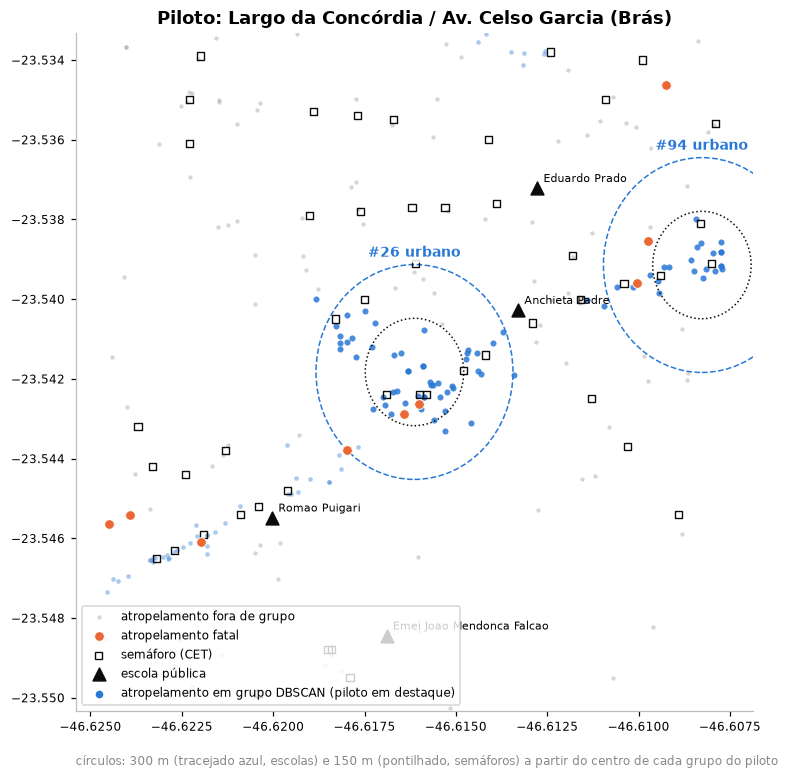

In [11]:
foco = piloto.sort_values("rank_prioridade").iloc[0]  # grupo do piloto mais bem colocado = centro do mapa
lat0, lon0 = foco.lat_centro, foco.lon_centro
JAN = 0.0085  # ~950 m para cada lado
con = sqlite3.connect(DB_PATH)
pts = pd.read_sql_query(f"""SELECT latitude, longitude, fatal, cluster_id FROM sinistros
                            WHERE latitude BETWEEN {lat0 - JAN} AND {lat0 + JAN}
                              AND longitude BETWEEN {lon0 - JAN} AND {lon0 + JAN}""", con)
con.close()
na_janela = lambda d: d[d["latitude"].between(lat0 - JAN, lat0 + JAN) & d["longitude"].between(lon0 - JAN, lon0 + JAN)]

fig, ax = plt.subplots(figsize=(8, 8))
fora = pts[pts["cluster_id"].isna()]
ax.scatter(fora["longitude"], fora["latitude"], s=8, color=CINZA, alpha=0.35, linewidths=0, label="atropelamento fora de grupo")
for cid, d in pts.dropna(subset=["cluster_id"]).groupby("cluster_id"):
    pil = cid in set(piloto["cluster_id"])
    ax.scatter(d["longitude"], d["latitude"], s=16 if pil else 9, color=AZUL, alpha=0.85 if pil else 0.4, linewidths=0)
f = pts[pts["fatal"] == 1]
ax.scatter(f["longitude"], f["latitude"], s=40, color=LARANJA, edgecolors="white", linewidths=0.6, label="atropelamento fatal", zorder=4)
s = na_janela(semaforos)
ax.scatter(s["longitude"], s["latitude"], marker="s", s=22, facecolors="none", edgecolors="#0b0b0b", linewidths=0.9,
           label="semáforo (CET)", zorder=3)
e = na_janela(escolas)
ax.scatter(e["longitude"], e["latitude"], marker="^", s=70, color="#0b0b0b", label="escola pública", zorder=5)
for _, r in e.iterrows():
    ax.annotate(r.nomes.title()[:28], (r.longitude, r.latitude), fontsize=7, xytext=(4, 4), textcoords="offset points")
k = 1 / np.cos(np.radians(lat0))
for _, g in piloto.iterrows():
    ax.add_patch(plt.Circle((g.lon_centro, g.lat_centro), 300 / 111_320, fill=False, ls="--", ec=AZUL, lw=1))
    ax.add_patch(plt.Circle((g.lon_centro, g.lat_centro), 150 / 111_320, fill=False, ls=":", ec="#0b0b0b", lw=1))
    ru = "—" if pd.isna(g.rank_urbano) else int(g.rank_urbano)
    ax.annotate(f"#{ru} urbano", (g.lon_centro, g.lat_centro + 300 / 111_320), fontsize=9, fontweight="bold",
                color=AZUL, ha="center", va="bottom", xytext=(0, 3), textcoords="offset points",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.scatter([], [], color=AZUL, s=16, label="atropelamento em grupo DBSCAN (piloto em destaque)")
ax.set_xlim(lon0 - JAN * k, lon0 + JAN * k); ax.set_ylim(lat0 - JAN, lat0 + JAN)
ax.set_aspect(k); ax.grid(False); ax.tick_params(labelsize=8)
ax.set_title("Piloto: Largo da Concórdia / Av. Celso Garcia (Brás)")
ax.legend(loc="lower left", fontsize=8, frameon=True)
ax.text(0, -0.08, "círculos: 300 m (tracejado azul, escolas) e 150 m (pontilhado, semáforos) a partir do centro de cada grupo do piloto",
        transform=ax.transAxes, fontsize=8, color=CINZA)
salvar(fig, "04_piloto_entorno.png")
plt.show()

## 6. Alagamento

> **PENDENTE: pontos de alagamento do CGE.** O CGE (Centro de Gerenciamento de Emergências) não publica os
> pontos de alagamento em formato aberto (CSV ou camada no GeoSampa): eles aparecem só no mapa em tempo real e
> nos boletins. Por isso esta base **não foi montada agora**. Há dois caminhos para ela entrar no projeto:
>
> 1. **Trabalho futuro:** pedir a série histórica ao CGE (Lei de Acesso à Informação) e cruzar com os grupos,
>    da mesma forma que as escolas (distância ao ponto de alagamento mais próximo e ocorrências por ano).
> 2. **Base simulada para a demonstração do modo "chuva":** alguns pontos marcados à mão a partir dos boletins
>    públicos, gravados na tabela `pontos_alagamento` (prevista em `src/central/schema.sql`) com `fonte`
>    identificando claramente que é **simulado/parcial**, para não passar como dado oficial.
>
> Até lá, o modo "chuva" do nó depende só da previsão de chuva (Open-Meteo), e não do histórico de
> alagamento no ponto.

## 7. Mapa interativo com o entorno

Novo mapa em `docs/evidencias/estudo_b/mapa_entorno.html`. O mapa do notebook 03 continua como está. As
camadas ligam e desligam no controle do canto superior direito:

- **Top 50 urbano**: círculos com raio proporcional ao peso e cor por presença de escola e semáforo;
- **Escolas** e **Semáforos (CET)**: só os que ficam a até 600 m de algum grupo do top 50 urbano. A cidade
  inteira teria ~6 mil semáforos e ~2,3 mil escolas, o arquivo ficaria pesado e o mapa ilegível;
- **Raios do piloto**: 300 m e 150 m em volta dos grupos do piloto.

In [12]:
top50 = clusters[clusters["rank_urbano"].between(1, 50)].copy()
T = rad(top50, "lat_centro", "lon_centro")
perto = lambda d: d[BallTree(T, metric="haversine").query(rad(d), k=1)[0][:, 0] * R_TERRA <= 600]
esc_m, sem_m, pis_m = perto(escolas), perto(semaforos), perto(piscantes)

def cor(g):
    if g.n_escolas_300m > 0 and not g.tem_semaforo: return "#b3261e"  # escola e sem semáforo
    if not g.tem_semaforo: return LARANJA
    if g.n_escolas_300m > 0: return "#7b4fd6"
    return AZUL

mapa = folium.Map(location=[-23.58, -46.62], zoom_start=11, tiles="OpenStreetMap")
c_top = folium.FeatureGroup(name="Top 50 urbano (pontos críticos)", show=True)
for _, g in top50.iloc[::-1].iterrows():
    popup = (f"<b>#{int(g.rank_urbano)} urbano · {g.via_principal.title()}</b><br>{g.vias.title()}<br>"
             f"fatais: {g.n_fatais} · não fatais: {g.n_nao_fatais} · índice: {g.indice_cet:.2f}<br>"
             f"escolas ≤ 300 m: {g.n_escolas_300m} (mais próxima: {g.distancia_escola_mais_proxima_m:.0f} m)<br>"
             f"{g.escolas_300m.title() if g.escolas_300m else ''}<br>"
             f"semáforos ≤ 150 m: {g.n_semaforos_150m} · piscantes: {g.n_piscantes_150m}")
    folium.CircleMarker([g.lat_centro, g.lon_centro], radius=4 + 1.6 * np.sqrt(g.peso), color=cor(g), weight=2,
                        fill=True, fill_opacity=0.55, popup=folium.Popup(popup, max_width=360),
                        tooltip=f"#{int(g.rank_urbano)} {g.via_principal.title()}").add_to(c_top)
c_esc = folium.FeatureGroup(name=f"Escolas públicas ({len(esc_m)} locais perto do top 50)", show=True)
for _, r in esc_m.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=4, color="#0b0b0b", weight=1, fill=True, fill_color="#ffd23f",
                        fill_opacity=1, tooltip=f"{r.tipos} {r.nomes.title()} ({r.redes.lower()})").add_to(c_esc)
c_sem = folium.FeatureGroup(name=f"Semáforos comuns CET ({len(sem_m)})", show=False)
for _, r in sem_m.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=2.5, color="#0b0b0b", weight=1, fill=True, fill_color="#0b0b0b",
                        fill_opacity=0.9, tooltip=f"semáforo · {r.nm_endereco}").add_to(c_sem)
c_pis = folium.FeatureGroup(name=f"Semáforos piscantes ({len(pis_m)})", show=False)
for _, r in pis_m.iterrows():
    folium.CircleMarker([r.latitude, r.longitude], radius=2.5, color="#a07800", weight=1, fill=True, fill_color="#f2c200",
                        fill_opacity=0.9, tooltip=f"piscante · {r.nm_endereco}").add_to(c_pis)
c_pil = folium.FeatureGroup(name="Piloto: raios de 300 m (escolas) e 150 m (semáforos)", show=True)
for _, g in piloto.iterrows():
    folium.Circle([g.lat_centro, g.lon_centro], radius=300, color=AZUL, weight=1.5, dash_array="6", fill=False).add_to(c_pil)
    folium.Circle([g.lat_centro, g.lon_centro], radius=150, color="#0b0b0b", weight=1, dash_array="2", fill=False).add_to(c_pil)
for camada in (c_top, c_esc, c_sem, c_pis, c_pil):
    camada.add_to(mapa)
legenda = """<div style="position: fixed; bottom: 24px; left: 12px; z-index: 9999; background: white; padding: 8px 10px;
 border: 1px solid #bbb; border-radius: 6px; font: 12px sans-serif; line-height: 1.5">
 <b>Cor dos pontos críticos</b><br>
 <span style="color:#b3261e">●</span> escola ≤ 300 m e sem semáforo ≤ 150 m<br>
 <span style="color:#eb6834">●</span> sem semáforo ≤ 150 m<br>
 <span style="color:#7b4fd6">●</span> escola ≤ 300 m, com semáforo<br>
 <span style="color:#2a78d6">●</span> com semáforo, sem escola<br>
 <span style="color:#0b0b0b">●</span><span style="color:#ffd23f">●</span> escola pública</div>"""
mapa.get_root().html.add_child(folium.Element(legenda))
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(EVID / "mapa_entorno.html")
print(f"salvo: {(EVID / 'mapa_entorno.html').relative_to(ROOT)} | escolas: {len(esc_m)} | semáforos: {len(sem_m)} "
      f"| piscantes: {len(pis_m)}")
mapa

salvo: docs\evidencias\estudo_b\mapa_entorno.html | escolas: 125 | semáforos: 645 | piscantes: 48


## 8. Checagem final no banco

In [13]:
with sqlite3.connect(DB_PATH) as con:
    display(pd.read_sql_query("""
        SELECT rank_urbano, via_principal, n_fatais, n_nao_fatais, ROUND(indice_cet, 2) AS indice_cet,
               n_escolas_300m, ROUND(distancia_escola_mais_proxima_m) AS dist_escola_m, n_semaforos_150m, tem_semaforo
        FROM clusters WHERE rank_urbano IS NOT NULL ORDER BY rank_urbano LIMIT 10""", con))
    display(pd.read_sql_query("""
        SELECT COUNT(*) AS grupos, SUM(n_escolas_300m > 0) AS com_escola_300m, SUM(tem_semaforo = 0) AS sem_semaforo_150m
        FROM clusters""", con))

,rank_urbano,via_principal,n_fatais,n_nao_fatais,indice_cet,n_escolas_300m,dist_escola_m,n_semaforos_150m,tem_semaforo
0,1,AVENIDA DO IMPERADOR,1,13,3.12,0,321.0,1,1
1,2,AVENIDA BRAZ LEME,2,2,3.75,0,423.0,1,1
2,3,AVENIDA DO ESTADO,2,14,4.24,0,371.0,2,1
3,4,ESTRADA DO M'BOI MIRIM,1,27,4.34,0,797.0,2,1
4,5,AVENIDA DONA BELMIRA MARIN,1,5,4.54,0,376.0,1,1
5,6,ACESSO ESTRADA DO M BOI MIRIM,3,63,5.44,0,385.0,5,1
6,7,AVENIDA JACUPESSEGO,2,7,5.63,0,370.0,0,0
7,8,AVENIDA LUIZ GUSHIKEN,2,2,5.96,0,332.0,2,1
8,9,AVENIDA JOSE PINHEIRO BORGES,2,17,6.11,1,182.0,1,1
9,10,RUA DEMAS ZITTO,1,5,6.68,5,98.0,0,0


,grupos,com_escola_300m,sem_semaforo_150m
0,290,140,53


## 9. Limitações

- **Distância em linha reta.** 300 m em linha reta pode ser bem mais a pé, se houver rio, linha de trem ou
  viaduto no meio. No Brás, a linha da CPTM/Metrô corta a região.
- **O raio parte do centróide.** Em grupos longos (~600 m), uma escola no fim do trecho pode ficar fora dos
  300 m. Ao mesmo tempo, o círculo de 150 m não cobre todo o trecho, o que pode marcar "sem semáforo" num
  grupo que tem semáforo na ponta.
- **Cadastro de semáforos de 2018** (`dt_carga` do GeoSampa). Semáforos instalados depois disso não aparecem.
  Para o piloto, vale confirmar em campo ou com a CET.
- **Um ponto por local semaforizado.** O cadastro não diz se há **foco para pedestre** nem quanto dura a
  travessia, e é isso que importa para idosos (notebook 01). `tem_semaforo` significa "há controle
  semafórico", não "a travessia é segura".
- **Escolas privadas e creches fora do indicador** (decisão da seção 2.1). Escolas particulares também geram
  fluxo de alunos e podem ser incluídas depois (camada `equipamento_educacao_rede_privada`).
- **Alagamento pendente** (seção 6).